# Task 2: Player Segment Classification EDA

Four-class classification of `segment` (Casual, Grinder, Social, Whale).

**Scope:** exploratory analysis only. No models are trained, evaluated, or tuned.

## 1. Dataset Loading

In [19]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
SEED = 342
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid', context='notebook')

# This notebook is stored in notebook/, so the data path remains portable.
DATA_ROOT = Path('../../cpe342-kaggle-main')

def quality_report(frame, id_col='player_id'):
    numeric = frame.select_dtypes(include=np.number)
    missing = pd.DataFrame({
        'missing_count': frame.isna().sum(),
        'missing_pct': frame.isna().mean().mul(100)
    }).sort_values('missing_count', ascending=False)
    print(f'Duplicate rows: {frame.duplicated().sum():,}')
    print(f'Duplicate {id_col}s: {frame[id_col].duplicated().sum():,}')
    print(f'Infinite numeric values: {np.isinf(numeric).sum().sum():,}')
    display(missing.query('missing_count > 0'))
    constants = frame.columns[frame.nunique(dropna=False).le(1)].tolist()
    near_constant = (frame.nunique(dropna=False) / len(frame)).sort_values().head(10)
    print('Constant features:', constants or 'None')
    display(near_constant.to_frame('unique_ratio'))
    return missing

def plot_missing(missing, title):
    shown = missing.query('missing_count > 0').head(25)
    if shown.empty:
        print('No missing values to plot.')
        return
    fig, ax = plt.subplots(figsize=(10, max(3, len(shown) * .3)))
    sns.barplot(data=shown.reset_index(), y='index', x='missing_pct', ax=ax, color='#4C72B0')
    ax.set(title=title, xlabel='Missing values (%)', ylabel='Column')
    plt.show(); plt.close()

def strong_correlations(frame, threshold=.75):
    corr = frame.select_dtypes(include=np.number).corr()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    pairs = upper.stack().rename('correlation').reset_index()
    return pairs.loc[pairs.correlation.abs().ge(threshold)].sort_values('correlation', key=np.abs, ascending=False)


In [20]:
train = pd.read_csv(DATA_ROOT / '02_multiclass_classification/train.csv')
print('Train shape:', train.shape)
print(f'Memory usage: {train.memory_usage(deep=True).sum()/1024**2:.2f} MiB')
display(train.head())
display(train.dtypes.rename('dtype').to_frame())
display(train.describe(include='all').T)
display(train.nunique(dropna=False).rename('unique_values').to_frame().sort_values('unique_values'))

test = pd.read_csv(DATA_ROOT / '02_multiclass_classification/test.csv')
print('Test shape:', test.shape)
print('Columns differing from train:', sorted(set(train.columns).symmetric_difference(test.columns)))
display(pd.DataFrame({'train_missing_pct': train.isna().mean().mul(100), 'test_missing_pct': test.isna().mean().mul(100)}).query('train_missing_pct > 0 or test_missing_pct > 0'))


Train shape: (104000, 46)
Memory usage: 41.80 MiB


,player_id,play_frequency,avg_session_duration,total_playtime_hours,login_streak,days_since_last_login,total_spending_thb,avg_monthly_spending,spending_frequency,friend_count,team_play_percentage,chat_activity_score,friend_invites_sent,gifts_sent_received,ranked_participation_rate,tournament_entries,competitive_rank,win_rate_ranked,watches_esports,achievement_completion_rate,collection_progress,rare_items_count,speed_of_progression,item_type_preference_cosmetic,item_type_preference_performance,item_type_preference_social,account_age_days,vip_tier,responds_to_discounts,preferred_game_mode,avg_match_length,peak_concurrent_hours,random_metric_1,random_metric_2,random_metric_3,region,platform,device_type,payment_method,language,account_status,player_type_tag,engagement_level,loyalty_tier,skill_tier,segment
0,P097760,21.076212,NaN,NaN,97.0,67.103422,72431.180593,3646.197510,17.712461,NaN,49.168211,14.034467,52.0,101.0,79.181597,1.0,5.0,25.000000,0.0,40.049422,47.950155,187.0,5.696086,0.590111,0.695405,0.579026,NaN,3.0,1.0,NaN,65.159025,63.831483,87.728566,0.877263,24.0,EU,PC,Phone,Card,NaN,Dormant,Collector,Low,Platinum,Diamond,2
1,P118291,7.909114,197.315042,976.440940,103.0,50.869211,50422.023411,4286.361523,7.755040,91.0,37.882354,189.272475,85.0,131.0,51.369634,4.0,4.0,58.570648,1.0,78.901247,58.440043,19.0,5.433415,0.403823,0.950000,0.495970,606.0,4.0,1.0,2.0,27.867062,79.292250,451.376826,NaN,121.0,APAC,Mobile,Laptop,Card,ES,Active,Social,High,Silver,NaN,3
2,P036138,2.520035,23.604288,1878.417029,61.0,74.477188,9970.156942,167.952963,36.403912,53.0,73.887185,54.001141,45.0,26.0,17.508806,30.0,10.0,49.627208,0.0,69.777741,NaN,23.0,2.127981,0.837043,0.615320,0.213740,169.0,5.0,0.0,0.0,18.646142,6.467460,862.503275,0.246006,133.0,AS,Console,Tablet,Card,JP,Dormant,Collector,Mid,Bronze,Platinum,0
3,P096415,15.678080,27.094268,678.992690,33.0,77.549945,17555.692929,1083.661525,44.751112,91.0,24.668608,6.945020,26.0,36.0,0.000000,16.0,6.0,62.473357,0.0,33.749659,32.528430,69.0,6.523443,0.738223,0.601918,0.214915,592.0,2.0,0.0,3.0,NaN,16.541956,302.682798,0.070138,142.0,LATAM,PC,Laptop,Card,KR,Active,Collector,Low,Platinum,Platinum,2
4,P045208,4.298657,NaN,1533.178518,73.0,79.350344,34814.668734,3773.956964,1.732425,91.0,34.835421,76.587481,54.0,NaN,20.868179,33.0,3.0,53.178108,0.0,46.173084,24.989892,73.0,4.380395,0.436947,0.533254,0.508812,1271.0,2.0,0.0,4.0,27.827175,10.466554,386.153572,0.801983,108.0,NaN,PC,Desktop,Wallet,JP,Active,Casual,Mid,NaN,Bronze,0


,dtype
player_id,str
play_frequency,float64
avg_session_duration,float64
total_playtime_hours,float64
login_streak,float64
days_since_last_login,float64
total_spending_thb,float64
avg_monthly_spending,float64
spending_frequency,float64
friend_count,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
player_id,104000,104000,P097760,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
play_frequency,95969.0,NaN,NaN,NaN,12.120569,7.06742,1.000035,6.464481,11.420109,16.865233,48.700382
avg_session_duration,96060.0,NaN,NaN,NaN,107.30042,54.250367,20.000564,64.031885,102.452165,143.739529,381.278343
total_playtime_hours,95997.0,NaN,NaN,NaN,1700.57479,942.451083,100.118337,965.467708,1635.500296,2341.12599,5992.590102
login_streak,95982.0,NaN,NaN,NaN,55.076035,35.427428,0.0,26.0,52.0,79.0,234.0
days_since_last_login,95949.0,NaN,NaN,NaN,45.962541,20.92454,0.007708,31.238284,45.82939,60.36002,136.202945
total_spending_thb,96126.0,NaN,NaN,NaN,34219.671058,22098.076113,500.474187,16335.228379,31572.320998,49016.415096,144500.577319
avg_monthly_spending,96146.0,NaN,NaN,NaN,3306.262106,1935.873247,100.052096,1778.197391,3163.923052,4614.338828,12960.918369
spending_frequency,96092.0,NaN,NaN,NaN,17.029999,9.616625,1.00001,9.480517,16.279288,23.570413,64.314508
friend_count,95948.0,NaN,NaN,NaN,107.576938,64.998944,0.0,56.0,103.0,152.0,414.0


,unique_values
watches_esports,3
responds_to_discounts,3
account_status,3
segment,4
platform,4
payment_method,4
device_type,5
region,5
player_type_tag,5
engagement_level,5


Test shape: (25889, 45)
Columns differing from train: ['segment']


,train_missing_pct,test_missing_pct
account_age_days,7.611538,7.837305
account_status,7.847115,7.740739
achievement_completion_rate,7.714423,7.458766
avg_match_length,7.761538,7.817992
avg_monthly_spending,7.551923,7.536019
avg_session_duration,7.634615,7.593959
chat_activity_score,7.747115,7.505118
collection_progress,7.707692,7.628723
competitive_rank,7.610577,7.999536
days_since_last_login,7.741346,7.420140


## 2. Dataset Overview

`player_id` is an identifier and should be excluded from future feature matrices unless a justified, leakage-safe use is established.

## 3. Data Quality Assessment

Duplicate rows: 0
Duplicate player_ids: 0
Infinite numeric values: 0


,missing_count,missing_pct
payment_method,31892,30.665385
region,27146,26.101923
account_status,8161,7.847115
platform,8113,7.800962
item_type_preference_social,8096,7.784615
item_type_preference_performance,8089,7.777885
random_metric_1,8080,7.769231
skill_tier,8074,7.763462
random_metric_2,8074,7.763462
avg_match_length,8072,7.761538


Constant features: None


,unique_ratio
watches_esports,0.000029
responds_to_discounts,0.000029
account_status,0.000029
segment,0.000038
platform,0.000038
payment_method,0.000038
device_type,0.000048
region,0.000048
player_type_tag,0.000048
engagement_level,0.000048


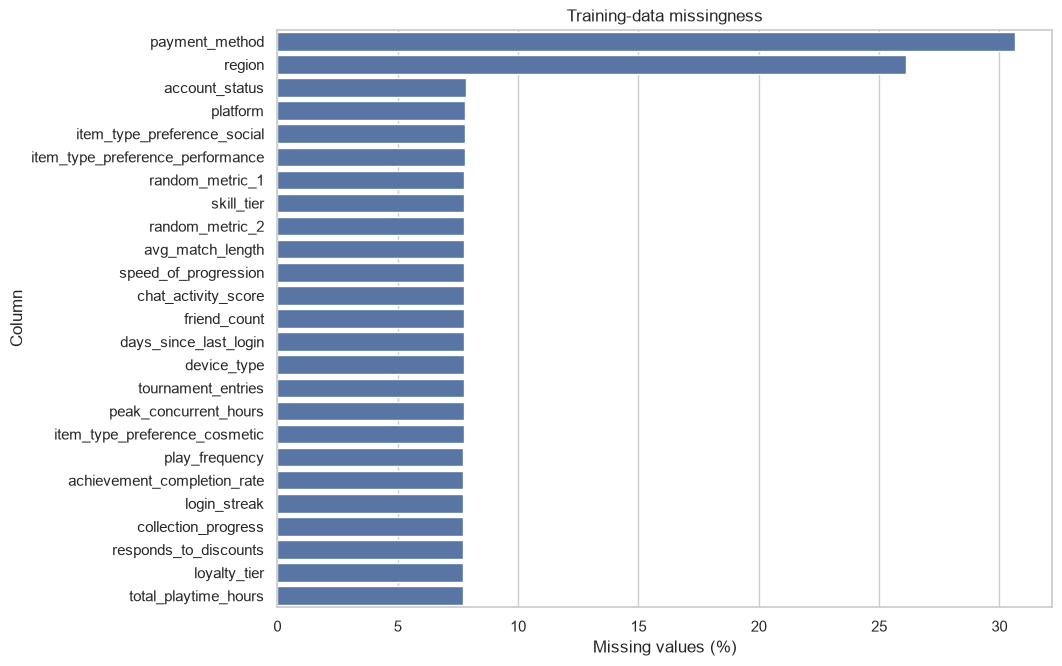

,min,1%,5%,50%,95%,99%,max
play_frequency,1.000035e+00,1.220963,2.111511,11.420109,24.845087,30.503992,48.700382
avg_session_duration,2.000056e+01,21.862965,29.155796,102.452165,204.371101,246.650925,381.278343
total_playtime_hours,1.001183e+02,135.746967,292.197582,1635.500296,3354.694576,4063.774048,5992.590102
login_streak,0.000000e+00,1.000000,5.000000,52.000000,119.000000,147.000000,234.000000
days_since_last_login,7.708368e-03,2.410007,11.017942,45.829390,80.894163,95.149030,136.202945
total_spending_thb,5.004742e+02,1116.723614,3716.466290,31572.320998,74413.928515,92423.117198,144500.577319
avg_monthly_spending,1.000521e+02,174.024425,463.014311,3163.923052,6740.671952,8224.740918,12960.918369
spending_frequency,1.000010e+00,1.377051,2.883646,16.279288,34.043041,41.521555,64.314508
friend_count,0.000000e+00,2.000000,12.000000,103.000000,223.000000,272.000000,414.000000
team_play_percentage,5.000000e+00,5.000000,17.085667,50.227977,83.088573,96.668526,100.000000


In [21]:
missing = quality_report(train)
plot_missing(missing, 'Training-data missingness')

# Examine numerical extremes without changing the data.
numeric_summary = train.select_dtypes(include=np.number).describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
display(numeric_summary[['min','1%','5%','50%','95%','99%','max']])

## 4. Target Analysis

,count,percent
segment,,
0,40934,39.359615
1,26034,25.032692
2,21014,20.205769
3,16018,15.401923


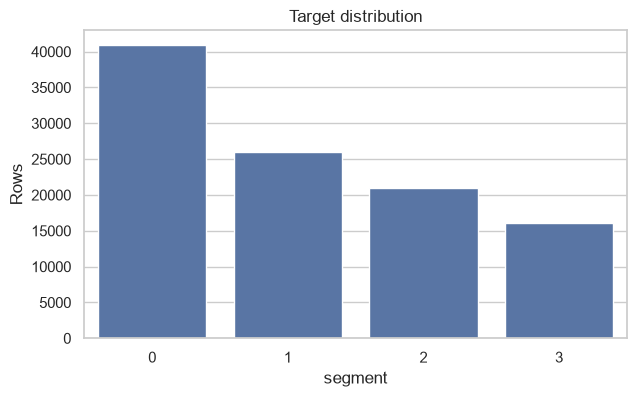

In [22]:
target_counts = train['segment'].value_counts(dropna=False).sort_index()
target_pct = target_counts.div(len(train)).mul(100)
display(pd.DataFrame({'count': target_counts, 'percent': target_pct}))
fig, ax = plt.subplots(figsize=(7,4))
sns.countplot(data=train, x='segment', ax=ax, color='#4C72B0')
ax.set(title='Target distribution', xlabel='segment', ylabel='Rows')
plt.show(); plt.close()

## 5. Feature Distribution Analysis

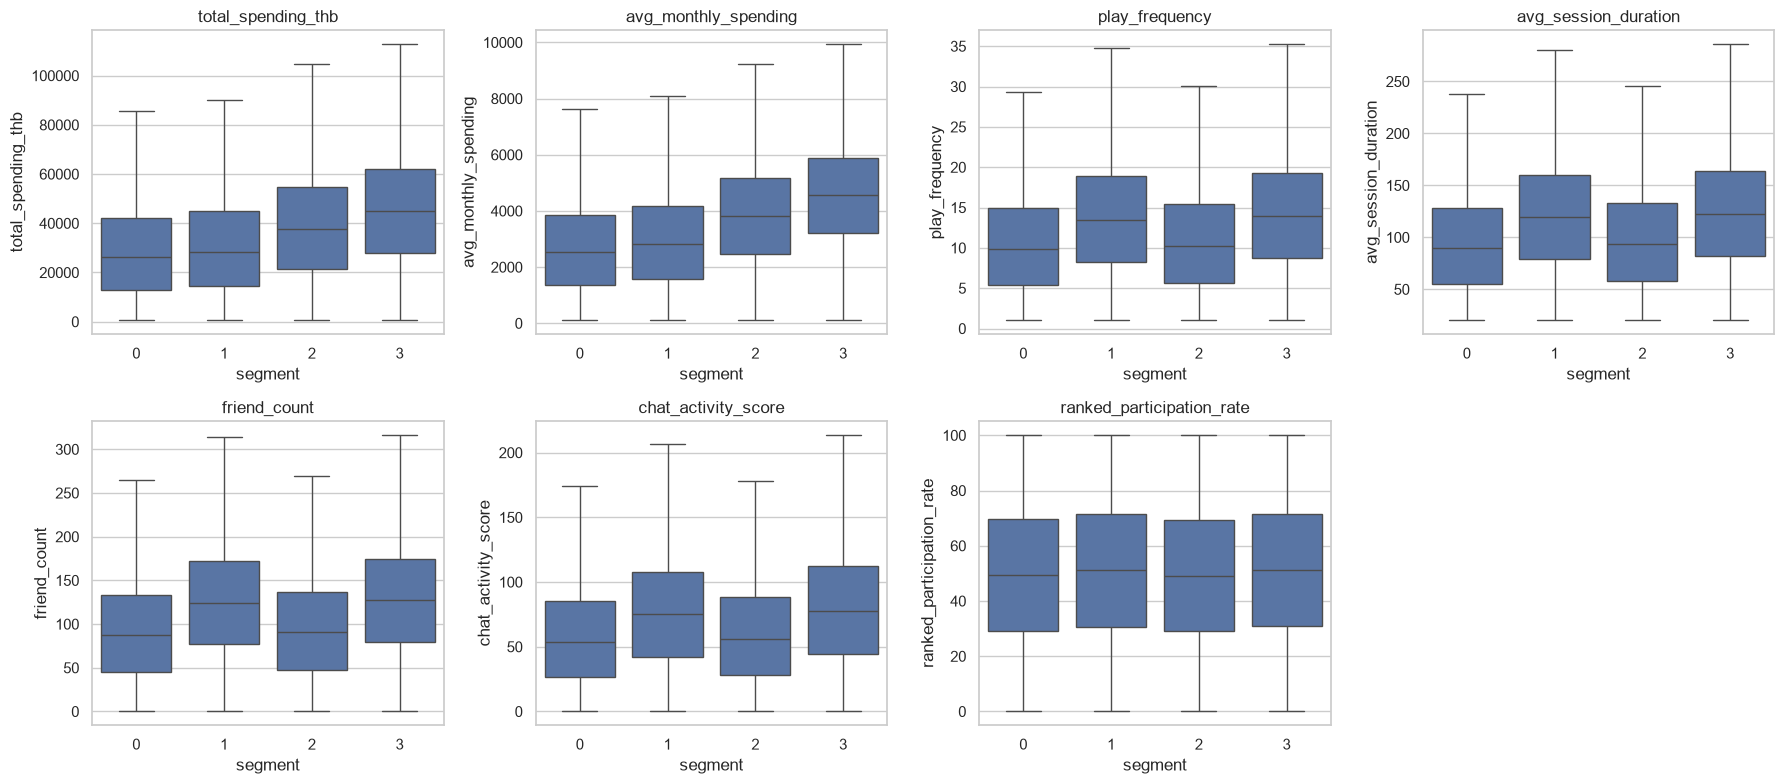

In [26]:
numeric_features = (
    train.select_dtypes(include=np.number)
    .columns.drop(['player_id', 'segment'], errors='ignore')
    .tolist()
)
cat_features = [
    col for col in train.select_dtypes(exclude=np.number).columns
    if col not in ['player_id', 'segment']
]
selected = ['total_spending_thb','avg_monthly_spending','play_frequency','avg_session_duration','friend_count','chat_activity_score','ranked_participation_rate']
fig, axes = plt.subplots(2,4,figsize=(18,8)); axes=axes.ravel()
for ax,col in zip(axes,selected):
    sns.boxplot(data=train, x='segment', y=col, showfliers=False, ax=ax)
    ax.set_title(col)
for ax in axes[len(selected):]: ax.remove()
plt.tight_layout(); plt.show(); plt.close()
for col in cat_features:
    rare = train[col].value_counts(normalize=True).mul(100).loc[lambda x: x < 1]
    if not rare.empty: print(f'{col}: rare levels (<1%): {rare.round(2).to_dict()}')

## 6. Feature Relationships

,level_0,level_1,correlation


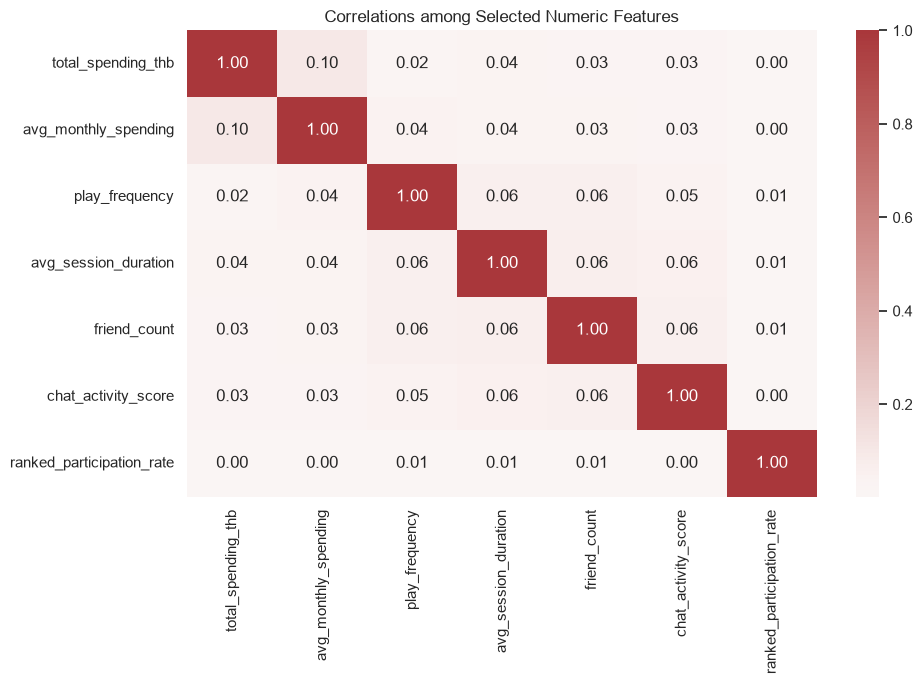

Feature-segment differences are examined using grouped distributions and medians, not correlations with the integer segment code.


In [24]:
# Exclude identifiers and nominal target
predictive_numeric = (
    train.select_dtypes(include=np.number)
    .drop(columns=['player_id', 'segment'], errors='ignore')
)

# Display strong correlations
display(strong_correlations(predictive_numeric))

# Select important features
focus = [
    'total_spending_thb',
    'avg_monthly_spending',
    'play_frequency',
    'avg_session_duration',
    'friend_count',
    'chat_activity_score',
    'ranked_participation_rate'
]

# Keep only existing numeric features
focus = [col for col in focus if col in predictive_numeric.columns]

# Correlation heatmap
if len(focus) >= 2:
    plt.figure(figsize=(10, 7))

    sns.heatmap(
        predictive_numeric[focus].corr(),
        cmap='vlag',
        center=0,
        annot=True,
        fmt='.2f'
    )

    plt.title('Correlations among Selected Numeric Features')
    plt.tight_layout()
    plt.show()
    plt.close()

print(
    'Feature-segment differences are examined using '
    'grouped distributions and medians, not correlations '
    'with the integer segment code.'
)

## 7. Task-Specific Analysis

In [25]:
segment_profile = train.groupby('segment')[['total_spending_thb','avg_monthly_spending','play_frequency','avg_session_duration','friend_count','chat_activity_score','team_play_percentage']].agg(['median','mean'])
display(segment_profile)
print('Interpretation: use the grouped distributions and profiles to identify discriminative features. Audit features such as player_type_tag, engagement_level, loyalty_tier, and skill_tier for possible label-derived definitions before modelling.')

total_spending_thb               avg_monthly_spending               \
                    median          mean               median         mean   
segment                                                                      
0             26099.539281  29201.074614          2554.162461  2737.115715   
1             28416.712414  31192.869844          2819.035780  2979.623576   
2             37728.878957  39079.027919          3817.461241  3869.173663   
3             45023.835787  45618.069498          4557.664192  4549.849343   

        play_frequency            avg_session_duration              \
                median       mean               median        mean   
segment                                                              
0             9.857623  10.705606            89.421770   95.448737   
1            13.436047  13.844230           119.389792  121.701748   
2            10.257823  11.079449            93.547918   99.143090   
3            13.955785  14.296666           122.859714  124.928059   

        friend_count             chat_activity_score             \
              median        mean              median       mean   
segment                                                           
0               87.0   92.989382           53.701144  59.280282   
1              124.0  125.990998           74.935491  77.264480   
2               91.0   96.552648           56.173186  61.348012   
3              127.0  129.296771           77.509674  80.021468   

        team_play_percentage             
                      median       mean  
segment                                  
0                  48.439374  48.508844  
1                  52.097066  52.226462  
2                  49.096005  49.176918  
3                  53.144702  52.889534

Interpretation: use the grouped distributions and profiles to identify discriminative features. Audit features such as player_type_tag, engagement_level, loyalty_tier, and skill_tier for possible label-derived definitions before modelling.


## 8. EDA Summary & Recommendations

### Key findings

- The training data has 104,000 rows and 46 columns, with no duplicate rows or duplicate player_id values.
- Class counts are Casual 40,934 (39.36%), Grinder 26,034 (25.03%), Social 21,014 (20.21%), and Whale 16,018 (15.40%). Future validation should be stratified.
- payment_method has 31,892 missing values, region 27,146, and account_status 8,161. Categorical missingness needs explicit treatment within future training folds.
- Segment is nominal. The notebook excludes it from Pearson correlation matrices and uses grouped distributions and medians for feature-to-segment comparison.
- Spending, engagement, loyalty, and self-described player attributes should be reviewed against the process that created segment labels.

### Recommendations

Exclude player_id. Audit player_type_tag, engagement_level, loyalty_tier, skill_tier, and spending-derived fields for label-definition leakage. Use fold-fitted categorical encoding, retain missingness information, and consider behavioural ratios such as spending per play-hour. No classifier is trained.
